## Homework 3: Numerical integration

**Course title:** Computer Simulation Methods in Physics (Phys 4071/5071; Fall 2025)  
**This homework assignment is due September 17, 2025, at 8 am.**   
(Submission via the shared `GitHub` repository.)

**Before you submit your homework, make sure that you click `Kernel > Restart & Run All`**.

## Quadrature errors

Consider the following definite integral:

$$
I = \int_{-1}^{1} dx \frac{1}{1+x^2} \equiv \frac{\pi}{2}
$$

* Plot the integrand function. What do you observe?
* Write a `Python` program that evaluates the integral $I$ numerically using (mid-point) `Riemann` (R), `Trapezoidal` (T), 6-th order `Romberg` (R), and `Gaussian` quadrature (G). Don't use any library for numerical quadrature. 
* Document each function thoroughly! Use the following template for the function:

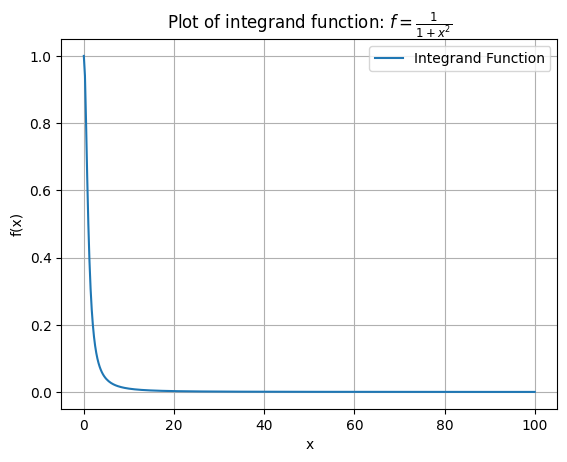

'\n\nThe main observation is that the function converges to approximately 0, within certain limits of x.\nIt also converges quickly. \n\n'

In [1]:
#Part A. Plotting of Integrand Function 

import math
import numpy as np 
import matplotlib.pyplot as plt 


f = lambda x : 1/(1+x**2)


x = np.linspace(0,100, 400)
y = f(x) 
plt.plot(x, y, label = "Integrand Function")
plt.title(r"Plot of integrand function: $f = \frac{1}{1+x^{2}}$")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.legend()
plt.grid()
plt.show()



"""

The main observation is that the function converges to approximately 0, within certain limits of x.
It also converges quickly. 

"""





In [2]:
#Part B1. Riemann Integration
import math
import numpy as np 
import matplotlib.pyplot as plt 



def integrator_Rieman(f, a, b, N, method = "midpoint"):
    ''' Computes the midpoint Riemann Sum of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].
    method : string
        Determines the kind of Riemann sum:
        "left": Sum using left endpoints.
        "Right": Sum using right endpoints.
        "Midpoint": Sum using (default) midpoints.

    Returns
    -------
    float
        Approximation of the integral given by the Riemann sum.
        
    '''
    x, dx = np.linspace(a, b, N+1, retstep=True) 
    if method == "left": 
        x_left = x[:-1]
        return np.sum(f(x_left)*dx) 
    elif method == "right": 
        x_right = x[1:]
        return np.sum(f(x_right)*dx) 
    elif method == "midpoint": 
        x_mid = (x[:-1] + x[1:])/2
        return np.sum(f(x_mid)*dx) 
    else:
        raise ValueError("Method must be 'left', 'right', or 'midpoint'.")
   
       


print(f" I(Riemann Sum) = {integrator_Rieman(f, a = -1, b = 1, N = 100, method = "midpoint")}")




    

 I(Riemann Sum) = 1.5708129934615018


In [3]:
#Part B2. Trapezoidal Method
import math
import numpy as np 
import matplotlib.pyplot as plt 



def integrator_Trap(f, a, b, N):
    ''' Computes the Trapezoidal Rule of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float
        Approximation of the integral given by the Trapezoidal Rule.
        
    '''
    x = np.linspace(a, b, N+1) 
    h = (b - a)/N 
    Integral = np.sum(f(x[1:-1]))*h + 0.5*h*(f(a) + f(b)) 
    return Integral
    
   
       


print(f" I(Trapezoidal Sum) = {integrator_Trap(f, a = -1, b = 1, N = 100)}")

 I(Trapezoidal Sum) = 1.5707629934616267


In [4]:
#Part B3. Romberg method
import math
import numpy as np 
import matplotlib.pyplot as plt 



def integrator_Trap(f, a, b, N):
    ''' Computes the Trapezoidal Rule of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float
        Approximation of the integral given by the Trapezoidal Rule.
        
    '''
    x = np.linspace(a, b, N+1) 
    h = (b - a)/N 
    Integral = np.sum(f(x[1:-1]))*h + 0.5*h*(f(a) + f(b)) 
    return Integral
    


def Romb_6(f, a, b, N): 
    ''' Computes the adapted Trapezoidal Rule (6th order Rhomberg) of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float
        Approximation of the integral given by the 6th-order Rhomberg up to element 3,3 for 6th-order error.
        
    '''

    #Trapezoidal rule elements within column 1.
    T_11 = integrator_Trap(f, a, b, N) 
    T_21 = integrator_Trap(f, a, b, 2*N) 
    T_31 = integrator_Trap(f, a, b, 4*N) 

    #Richardson approx elements that make up the triangular matrix pieces.
    T_22 = T_21 + (1.0/3.0)*(T_21 - T_11)
    T_32 = T_31 + (1.0/3.0)*(T_31 - T_21)
    T_33 = T_32 + (1.0/15.0)*(T_32 - T_22)


    return T_33 


#Main integrand function
f = lambda x : 1/(1+x**2)


print(f" I(Rhomberg) = {Romb_6(f, a = -1, b = 1, N = 100)}")

 I(Rhomberg) = 1.5707963267948977


In [5]:
#Part B4. Gauss-Legendre Method 
import math
import numpy as np 
import matplotlib.pyplot as plt 
from numpy.polynomial import Legendre as P


#Main integrand function
f = lambda x : 1/(1+x**2)


def Gauss_legendre(f, N): 

    ''' Computes the Gauss-Legendre of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 

    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float
        Approximation of the integral given by the  Gauss-Legendre method.
        
    '''


    
    # generate Legendre Polynomial 
    Leg = P.basis(N)

    # use roots() method to find roots
    roots = Leg.roots()

    # calculate derivatives of P3 at the roots
    Leg_prime = Leg.deriv(1)(roots)

    # calculate the weights
    w=[]
    for i in range(0, N, 1): 
        w.append(2.0/((1 - roots[i]**2)*(Leg_prime[i]**2)))

    #test function with roots inputted
    function = f(roots)

    #dot product applied here 
    Integral = np.dot(function, w) 


    return Integral 




print(f" I(Gauss) = {Gauss_legendre(f, N = 100)}")

    
        



 I(Gauss) = 1.5707963267948957


Compare the relative error  

$$
\epsilon = \left| \frac{I_\mathrm{approx} - I_\mathrm{exact}}{I_\mathrm{exact}} \right|
$$

for these different quadrature rules. To do so, make a table of the following form

| N  | R-Rule | T-Rule | ... | $\epsilon_R$ | $\epsilon_T$ | ... |
|----|--------|--------|--------|--------------|--------------|--------------|
| 4 | $\vdots$ | $\vdots$ | $\vdots$ | $\vdots$       | $\vdots$       | $\vdots$       |
| 6 | $\vdots$ | $\vdots$ | $\vdots$ | $\vdots$       | $\vdots$       | $\vdots$       |
| $\vdots$ | $\vdots$ | $\vdots$ | $\vdots$ | $\vdots$       | $\vdots$       | $\vdots$       |
| 120 | $\vdots$ | $\vdots$ | $\vdots$ | $\vdots$       | $\vdots$       | $\vdots$       |

In [6]:
#Part C1. Relative error table 
import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from numpy.polynomial import Legendre as P


#Main integrand function
f = lambda x : 1/(1+x**2)



def integrator_Rieman(f, a, b, N, method = "midpoint"):
    ''' Computes the midpoint Riemann Sum of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].
    method : string
        Determines the kind of Riemann sum:
        "left": Sum using left endpoints.
        "Right": Sum using right endpoints.
        "Midpoint": Sum using (default) midpoints.

    Returns
    -------
    float
        Approximation of the integral given by the Riemann sum.
        
    '''
    x, dx = np.linspace(a, b, N+1, retstep=True) 
    if method == "left": 
        x_left = x[:-1]
        return np.sum(f(x_left)*dx) 
    elif method == "right": 
        x_right = x[1:]
        return np.sum(f(x_right)*dx) 
    elif method == "midpoint": 
        x_mid = (x[:-1] + x[1:])/2
        return np.sum(f(x_mid)*dx) 
    else:
        raise ValueError("Method must be 'left', 'right', or 'midpoint'.")
   
       


def integrator_Trap(f, a, b, N):
    ''' Computes the Trapezoidal Rule of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float
        Approximation of the integral given by the Trapezoidal Rule.
        
    '''
    x = np.linspace(a, b, N+1) 
    h = (b - a)/N 
    Integral = np.sum(f(x[1:-1]))*h + 0.5*h*(f(a) + f(b)) 
    return Integral
    
   
       

def Romb_6(f, a, b, N): 
    ''' Computes the adapted Trapezoidal Rule (6th order Rhomberg) of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float
        Approximation of the integral given by the 6th-order Rhomberg up to element 3,3 for 6th-order error.
        
    '''

    #Trapezoidal rule elements within column 1.
    T_11 = integrator_Trap(f, a, b, N) 
    T_21 = integrator_Trap(f, a, b, 2*N) 
    T_31 = integrator_Trap(f, a, b, 4*N) 

    #Richardson approx elements that make up the triangular matrix pieces.
    T_22 = T_21 + (1.0/3.0)*(T_21 - T_11)
    T_32 = T_31 + (1.0/3.0)*(T_31 - T_21)
    T_33 = T_32 + (1.0/15.0)*(T_32 - T_22)


    return T_33 





def Gauss_legendre(f, N): 

    ''' Computes the Gauss-Legendre of f(x) over the interval [a = -1 ,b = 1]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 

    N : integer
        Number of subintervals of equal length in the partition of [a = -1 ,b  = 1].

    Returns
    -------
    float
        Approximation of the integral given by the  Gauss-Legendre method.
        
    '''


    
    # generate Legendre Polynomial 
    Leg = P.basis(N)

    # use roots() method to find roots
    roots = Leg.roots()

    # calculate derivatives of P3 at the roots
    Leg_prime = Leg.deriv(1)(roots)

    # calculate the weights
    w=[]
    for i in range(0, N, 1): 
        w.append(2.0/((1 - roots[i]**2)*(Leg_prime[i]**2)))

    #test function with roots inputted
    function = f(roots)

    #dot product applied here 
    Integral = np.dot(function, w) 


    return Integral 



#True value of integral 
I_true = math.pi/2.0



def Int_Table(N): 
    ''' Displays and computes the 6 different quadrature rules and relative errors compared to the true value. 

    Parameters
    ----------
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    Panda DataFrame
        Returns pandas DataFrame table that displays the integration values and errors of the 6 rules. 
        
    '''
    Table = [] 
    for i in range(4, N+1, 2):
        RM = integrator_Rieman(f,  -1,  1, i) 
        TrP = integrator_Trap(f, -1,  1, i)
        Rom =  Romb_6(f,  -1,  1, i)
        Gauss = Gauss_legendre(f, i)
        err_RM = (abs(RM - I_true))/(abs(I_true))
        err_TrP = (abs(TrP - I_true))/(abs(I_true))
        err_Rom = (abs(Rom - I_true))/(abs(I_true))
        err_G = (abs(Gauss - I_true))/(abs(I_true))
        Table.append({
            "N": i, 
            "R-Rule": f"{RM:.8f}", 
            "T-Rule": f"{TrP:.8f}", 
            "Rom6-Rule": f"{Rom:.8f}", 
            "Gauss-Rule": f"{Gauss:.8f}", 
            "eps_R": f"{err_RM:1.15e}", 
            "eps_T": f"{err_TrP:1.15e}", 
            "eps_Rom": f"{err_Rom:1.15e}", 
            "eps_G": f"{err_G:1.15e}"
        })
    return pd.DataFrame(Table)
    
        
        

df = Int_Table(120)
print(df.to_string(index=False)) 












            

  N     R-Rule     T-Rule  Rom6-Rule Gauss-Rule                 eps_R                 eps_T               eps_Rom                 eps_G
  4 1.58117647 1.55000000 1.57079705 1.56862745 6.608204778858140e-03 1.323935283024885e-02 4.585368806794605e-07 1.380749227324065e-03
  6 1.57542460 1.56153846 1.57079635 1.57073171 2.946453374606939e-03 5.893740072161541e-03 1.400782366574914e-08 4.113803726239678e-05
  8 1.57340026 1.56558824 1.57079633 1.57079441 1.657714853069424e-03 3.315574025695497e-03 2.404121489290261e-09 1.218648656603044e-06
 10 1.57246293 1.56746306 1.57079633 1.57079627 1.060993827358974e-03 2.122025518230511e-03 6.308997741446077e-10 3.601461371961192e-08
 12 1.57195371 1.56848153 1.57079633 1.57079633 7.368153315485353e-04 1.473643348777301e-03 2.114021400498143e-10 1.063009933168241e-09
 14 1.57164666 1.56909565 1.57079633 1.57079633 5.413381444380955e-04 1.082681320533063e-03 8.385553621376439e-11 3.135136360612218e-11
 16 1.57144736 1.56949425 1.57079633 1.57079633 

Make a plot of $\log_{10} \epsilon$ versus $\log_{10} N$. 
Note that the ordinate is
effectively the number of decimal places of precision.



Use the plot to determine the power-law dependence of the error on the number of
points $N$. (Notice that you may not be able to reach the roundoff error regime for the
trapezoidal rule because the approximation error is so large.)

p(Rieman, Trap, R-6, Gauss) =  -1.999744047884322
p(Rieman, Trap, R-6, Gauss) =  -1.9998702154623926
p(Rieman, Trap, R-6, Gauss) =  -6.050601379939432
p(Rieman, Trap, R-6, Gauss) =  -17.785587864666244


Text(0, 0.5, 'log_error')

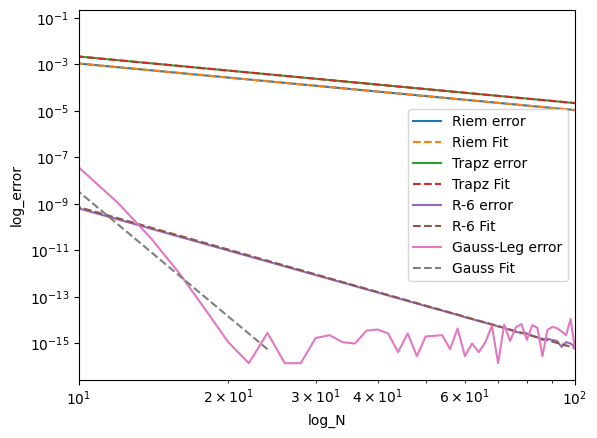

In [7]:
#Part C2. Relative Error Plots and fitting 
import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from numpy.polynomial import Legendre as P




def powerlaw(N, Y): 
    '''
    Performs a linear regression for a power law function that will be usable in log-scale fits.

    Parameters
    ----------
    N: array-like
        Independent variable values.
    Y: array-like
        Dependent variable values corresponding to N. (These are errors)

    Returns
    -------
    array-like
        generalised power law function Y = C*N**P, for log-scale purposes, will be used as a linear function. 
    '''
    
    coeffs = np.polyfit(np.log(N), np.log(Y), 1)
    p, logC = coeffs[0], coeffs[1]
    C = np.exp(logC)
    Y = C*N**p
    print("p(Rieman, Trap, R-6, Gauss) = ", p)
    return Y 
    
    
# get N values
N_vals = df["N"].to_numpy(dtype = int)

# get error columns
eps_R   = df["eps_R"].to_numpy(dtype = float)
eps_T   = df["eps_T"].to_numpy(dtype = float)
eps_Rom = df["eps_Rom"].to_numpy(dtype = float)
eps_G   = df["eps_G"].to_numpy(dtype = float)


#plotting parameters
plt.loglog(N_vals, eps_R , label="Riem error")
plt.loglog(N_vals, powerlaw(N_vals, eps_R), "--", label = "Riem Fit")
plt.loglog(N_vals, eps_T , label="Trapz error")
plt.loglog(N_vals, powerlaw(N_vals, eps_T), "--", label = "Trapz Fit")
plt.loglog(N_vals, eps_Rom , label="R-6 error")
plt.loglog(N_vals[0:51], powerlaw(N_vals[0:51], eps_Rom[0:51]), "--", label = "R-6 Fit")
plt.loglog(N_vals, eps_G , label="Gauss-Leg error")
plt.loglog(N_vals[0:11], powerlaw(N_vals[0:11], eps_G[0:11]), "--", label = "Gauss Fit")
plt.legend(loc="best")
plt.xlim(10**1, 10**2)
plt.xlabel("log_N")
plt.ylabel("log_error")











How would you analyze your integration results if you didn't know the exact answer? Consider the integral

$$
I = \int_0^1 dx \frac{x^4(1-x^2)^4 \; \cos (5x)}{1+x^2}
$$

Use the different quadrature rules as a tool to analyze the numerical convergence (and error) of your result.

# HW #3 — Gauss–Legendre Adaptation

We start with

$$
I = \int dx \, \frac{x^4 (1-x^2)^4 \cos(5x)}{1+x^2}.
$$

---

From the linear mapping formula

$$
\tilde{x}(x) = \frac{1}{b-a}(2x - (b+a)),
$$

with $a=0$, $b=1$:

$$
\tilde{x}(x) = \frac{1}{1}(2x - (1)) = (2x-1).
$$

---

We set

$$
u = (2x-1), \qquad du = 2dx.
$$

---

This gives

$$
I = \frac{1}{2}\int du \, 
\frac{\left(\frac{u+1}{2}\right)^4 \left(1 - \left(\frac{u+1}{2}\right)^2\right)^4 
\cos\!\left(5\cdot \frac{u+1}{2}\right)}
{1 + \left(\tfrac{u+1}{2}\right)^2}.
$$

---

Thus the bounds are adapted to $u \in [-1,1]$, suitable for Gauss–Legendre quadrature. The u-substituted form of the integrand is what will be used for Gauss-legendre testing. 




In [8]:
#Part D. Inexactness integration and error convergence
import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from numpy.polynomial import Legendre as P


#Main integrand functions
f = lambda x : (x**4 * (1- x**2)**4 * np.cos(5*x))/(1 + x**2)
f_2 = lambda u: (0.5*((u/2.0) + (1.0/2.0))**4 * (1 - ((u/2.0) + (1.0/2.0))**2)**4 * np.cos(5*((u/2.0) + (1.0/2.0))))/(1 + ((u/2.0) + (1.0/2.0))**2)





def integrator_Rieman(f, a, b, N, method = "midpoint"):
    ''' Computes the midpoint Riemann Sum of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].
    method : string
        Determines the kind of Riemann sum:
        "left": Sum using left endpoints.
        "Right": Sum using right endpoints.
        "Midpoint": Sum using (default) midpoints.

    Returns
    -------
    float
        Approximation of the integral given by the Riemann sum.
        
    '''
    x, dx = np.linspace(a, b, N+1, retstep=True) 
    if method == "left": 
        x_left = x[:-1]
        return np.sum(f(x_left)*dx) 
    elif method == "right": 
        x_right = x[1:]
        return np.sum(f(x_right)*dx) 
    elif method == "midpoint": 
        x_mid = (x[:-1] + x[1:])/2
        return np.sum(f(x_mid)*dx) 
    else:
        raise ValueError("Method must be 'left', 'right', or 'midpoint'.")
   
       


def integrator_Trap(f, a, b, N):
    ''' Computes the Trapezoidal Rule of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float
        Approximation of the integral given by the Trapezoidal Rule.
        
    '''
    x = np.linspace(a, b, N+1) 
    h = (b - a)/N 
    Integral = np.sum(f(x[1:-1]))*h + 0.5*h*(f(a) + f(b)) 
    return Integral
    
   
       

def Romb_6(f, a, b, N): 
    ''' Computes the adapted Trapezoidal Rule (6th order Rhomberg) of f(x) over the interval [a,b]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 
    a , b : integers
            The endpoints of the integrand [a,b]. 
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    float
        Approximation of the integral given by the 6th-order Rhomberg up to element 3,3 for 6th-order error.
        
    '''

    #Trapezoidal rule elements within column 1.
    T_11 = integrator_Trap(f, a, b, N) 
    T_21 = integrator_Trap(f, a, b, 2*N) 
    T_31 = integrator_Trap(f, a, b, 4*N) 

    #Richardson approx elements that make up the triangular matrix pieces.
    T_22 = T_21 + (1.0/3.0)*(T_21 - T_11)
    T_32 = T_31 + (1.0/3.0)*(T_31 - T_21)
    T_33 = T_32 + (1.0/15.0)*(T_32 - T_22)


    return T_33 





def Gauss_legendre(f, N): 

    ''' Computes the Gauss-Legendre of f(x) over the interval [a = -1 ,b = 1]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 

    N : integer
        Number of subintervals of equal length in the partition of [a = -1 ,b  = 1].

    Returns
    -------
    float
        Approximation of the integral given by the  Gauss-Legendre method.
        
    '''


    
    # generate Legendre Polynomial 
    Leg = P.basis(N)

    # use roots() method to find roots
    roots = Leg.roots()

    # calculate derivatives of P3 at the roots
    Leg_prime = Leg.deriv(1)(roots)

    # calculate the weights
    w=[]
    for i in range(0, N, 1): 
        w.append(2.0/((1 - roots[i]**2)*(Leg_prime[i]**2)))

    #test function with roots inputted
    function = f(roots)

    #dot product applied here 
    Integral = np.dot(function, w) 


    return Integral 





def Int_Table(N): 
    ''' Displays and computes the 6 different quadrature rules and relative errors compared to the true value. 

    Parameters
    ----------
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    Panda DataFrame
        Returns pandas DataFrame table that displays the integration values and errors of the 6 rules. (didn't use errors for this one)
        
    '''
    Table = [] 
    for i in range(1,N+1):
        RM = integrator_Rieman(f,  0,  1, i) 
        TrP = integrator_Trap(f, 0,  1, i)
        Rom =  Romb_6(f,  0,  1, i)
        Gauss = Gauss_legendre(f_2, i)
        Table.append({
            "N": i, 
            "R-Rule": f"{RM:.8f}", 
            "T-Rule": f"{TrP:.8f}", 
            "Rom6-Rule": f"{Rom:.8f}", 
            "Gauss-Rule": f"{Gauss:.8f}", 
        })
    return pd.DataFrame(Table)
    
        
        

df = Int_Table(40)
print(df.to_string(index=False)) 






 N      R-Rule      T-Rule   Rom6-Rule  Gauss-Rule
 1 -0.01267434  0.00000000 -0.00353599 -0.01267434
 2 -0.00259605 -0.00633717 -0.00455135 -0.00130207
 3 -0.00450367 -0.00448409 -0.00449898 -0.00565121
 4 -0.00452731 -0.00446661 -0.00449729 -0.00426451
 5 -0.00450775 -0.00448722 -0.00449753 -0.00450917
 6 -0.00450136 -0.00449388 -0.00449762 -0.00450195
 7 -0.00449920 -0.00449611 -0.00449766 -0.00449712
 8 -0.00449837 -0.00449696 -0.00449767 -0.00449770
 9 -0.00449803 -0.00449732 -0.00449767 -0.00449768
10 -0.00449787 -0.00449749 -0.00449768 -0.00449768
11 -0.00449779 -0.00449757 -0.00449768 -0.00449768
12 -0.00449774 -0.00449762 -0.00449768 -0.00449768
13 -0.00449772 -0.00449764 -0.00449768 -0.00449768
14 -0.00449771 -0.00449765 -0.00449768 -0.00449768
15 -0.00449770 -0.00449766 -0.00449768 -0.00449768
16 -0.00449769 -0.00449767 -0.00449768 -0.00449768
17 -0.00449769 -0.00449767 -0.00449768 -0.00449768
18 -0.00449769 -0.00449767 -0.00449768 -0.00449768
19 -0.00449768 -0.00449768 -0.0

**Error and Convergence Notes**

Because of time constraints, I didn't have associated method errors for each quadrature, but key properties from the integration values themselves are that the $R-6$ quadrature has the fastest convergence, which makes sense, being 6th order error. How I would have approached the errors themselves are to calculate each quadrature approximation error and follow the same iteration then plot over N to see which quadrature falls off faster. From the table, it could still be Romberg-6. 


## Legendre series

Expand the following function in a Legendre series:

$$
f(x) = \frac{1}{2} \left( 30x^3 - 2 \right) \,.
$$

Is the Legendre series finite (i.e., truncates after a finite number of terms)? If so, why?

Check that your Legendre series is correct.

**Hint:** A Legendre series has the following form:

$$
f(x) = \sum_{\ell=0}^\infty a_\ell P_\ell(x)
$$

# Legendre Series Expansion

We are asked to expand the following function in a Legendre series:

$$
f(x) = \tfrac{1}{2} \left( 30x^3 - 2 \right).
$$

A Legendre series has the form

$$
f(x) = \sum_{\ell=0}^\infty a_\ell P_\ell(x),
$$

where $P_\ell(x)$ are the Legendre polynomials.

---

## Step 1: Recall the first few Legendre polynomials

$$
\begin{aligned}
P_0(x) &= 1, \\
P_1(x) &= x, \\
P_2(x) &= \tfrac{1}{2}(3x^2 - 1), \\
P_3(x) &= \tfrac{1}{2}(5x^3 - 3x).
\end{aligned}
$$

---

## Step 2: Express $x^3$ in terms of Legendre polynomials

From $P_3(x) = \tfrac{1}{2}(5x^3 - 3x)$, solve for $x^3$:

$$
x^3 = \frac{2}{5} P_3(x) + \frac{3}{5} P_1(x).
$$

---

## Step 3: Rewrite $f(x)$ in terms of $P_\ell(x)$

$$
\begin{aligned}
f(x) &= \tfrac{1}{2}(30x^3 - 2) \\
&= \tfrac{1}{2}\left(30\left(\tfrac{2}{5}P_3(x) + \tfrac{3}{5}P_1(x)\right) - 2P_0(x)\right) \\
&= \tfrac{1}{2}\left(12P_3(x) + 18P_1(x) - 2P_0(x)\right) \\
&= 6P_3(x) + 9P_1(x) - P_0(x).
\end{aligned}
$$

So:

$$
f(x) = -P_0(x) + 9P_1(x) + 6P_3(x).
$$

---

## Step 4: Orthogonality check

Since Legendre polynomials are orthogonal on $[-1,1]$,

$$
\int_{-1}^1 P_\ell(x) P_m(x) \, dx = 0 \quad \text{for } \ell \neq m.
$$

Thus the coefficients are

$$
a_m = \frac{2m+1}{2} \int_{-1}^1 f(x) P_m(x)\, dx.
$$

---

## Step 5: Compute coefficients

### For $\ell = 0$:

$$
a_0 = \frac{1}{2} \int_{-1}^1 (30x^3 - 2)\, dx.
$$

Compute:

$$
\int_{-1}^1 30x^3\, dx = 30 \left[\frac{x^4}{4}\right]_{-1}^1 = 30\left(\frac{1}{4} - \frac{1}{4}\right) = 0,
$$

$$
\int_{-1}^1 (-2)\, dx = -2(2) = -4.
$$

So:

$$
a_0 = \frac{1}{2}(-4) = -2.
$$

---

### For $\ell = 1$:

Since $P_1(x) = x$,

$$
a_1 = \frac{3}{2} \int_{-1}^1 f(x) P_1(x)\, dx
= \frac{3}{2} \int_{-1}^1 (15x^3 - 1)x \, dx.
$$

Simplify:

$$
a_1 = \frac{3}{2}\int_{-1}^1 (15x^4 - x)\, dx.
$$

Compute:

$$
\int_{-1}^1 15x^4\, dx = 15\left[\frac{x^5}{5}\right]_{-1}^1 = 15\left(\frac{1}{5} - \frac{-1}{5}\right) = 6,
$$

$$
\int_{-1}^1 x\, dx = \left[\tfrac{x^2}{2}\right]_{-1}^1 = \tfrac{1}{2} - \tfrac{1}{2} = 0.
$$

Thus:

$$
a_1 = \frac{3}{2}(6 - 0) = 9.
$$

---

### For $\ell = 3$:

Since $P_3(x) = \tfrac{1}{2}(5x^3 - 3x)$,

$$
a_3 = \frac{7}{2} \int_{-1}^1 f(x) P_3(x)\, dx.
$$

Substitute $f(x) = 15x^3 - 1$:

$$
a_3 = \frac{7}{2} \int_{-1}^1 (15x^3 - 1)\cdot \tfrac{1}{2}(5x^3 - 3x)\, dx.
$$

Expand:

$$
a_3 = \frac{7}{4} \int_{-1}^1 (75x^6 - 45x^4 - 5x^3 + 3x)\, dx.
$$

Now compute terms:

- $\int_{-1}^1 75x^6\, dx = 75\left[\tfrac{x^7}{7}\right]_{-1}^1 = 75\left(\tfrac{1}{7} - \tfrac{-1}{7}\right) = \tfrac{150}{7}$.

- $\int_{-1}^1 -45x^4\, dx = -45\left[\tfrac{x^5}{5}\right]_{-1}^1 = -45\left(\tfrac{1}{5} - \tfrac{-1}{5}\right) = -18.$

- $\int_{-1}^1 -5x^3\, dx = -5\left[\tfrac{x^4}{4}\right]_{-1}^1 = -5\left(\tfrac{1}{4} - \tfrac{1}{4}\right) = 0.$

- $\int_{-1}^1 3x\, dx = 3\left[\tfrac{x^2}{2}\right]_{-1}^1 = 3\left(\tfrac{1}{2} - \tfrac{1}{2}\right) = 0.$

So:

$$
a_3 = \frac{7}{4}\left(\tfrac{150}{7} - 18\right)  = 6.
$$

---

## Step 6: Final Answer

Therefore, the Legendre expansion is:

$$
f(x) = -P_0(x) + 9P_1(x) + 6P_3(x).
$$

---

## Explanation of truncation

The expansion truncates because $f(x)$ is a cubic polynomial. Legendre polynomials form a complete basis up to any degree, so higher terms vanish by orthogonality.


## Black-body radiation

The integral
\begin{equation}
I = \int_0^{\infty} \frac{x^3}{e^x -1} dx
\end{equation}
appears in Planck's treatment of black-body radiation. 

Evaluate this integral numerically with `Gauss-Legendre` integration by mapping the interval $(0,1) \rightarrow (0,\infty)$ using your favorite map. The (absolute) accuracy goal is $10^{-8}$.

# Black-body radiation — mapping 

Start with
$$
I=\int_{0}^{\infty}\frac{x^{3}}{e^{x}-1}\,dx.
$$

Use the substitution
$$
z=\frac{x}{1+x}.
$$

Solve for $x$:
$$
z(1+x)=x \;\Rightarrow\; z+zx=x \;\Rightarrow\; z=x(1-z)
\;\Rightarrow\; x=\frac{z}{1-z}.
$$

Differentiate:
$$
dz=\frac{1}{(1+x)^2}\,dx
\quad\Rightarrow\quad
dx=(1+x)^2\,dz.
$$

With (x=$\frac{z}{1-z}$) this gives
$$
dx=\left(\frac{1}{1-z}\right)^2 dz=\frac{dz}{(1-z)^2}.
$$

Substitute into the integral 
$$
I=\int_{0}^{1}
\frac{\left(\dfrac{z}{1-z}\right)^{3}}{e^{\left(\dfrac{z}{1-z}\right)}-1}\,
\left(\frac{1}{1-z}\right)^{2}dz.
$$

---

Now map $(0,1)\to(-1,1)$ using
$$
u=2z-1,\qquad z=\frac{u+1}{2},\qquad dz=\frac{du}{2},
\qquad 1-z=\frac{1-u}{2}.
$$

Plug these into the previous line **without extra simplification**:
$$
I=\frac{1}{2}\int_{-1}^{1}
\frac{\left(\dfrac{u+1}{-u+1}\right)^{3}
\left(\dfrac{2}{-u+1}\right)^{2}}
{e^{\left(\dfrac{u+1}{-u+1}\right)}-1}\;du.
$$

This is the final mapped function on \([-1,1]\).


In [9]:
#Black Body Gauss_Legendre 
import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from numpy.polynomial import Legendre as P


#Main integrand functions
f_a = lambda u: 0.5*((pow(((u+1.0)/(-u + 1.0)),3) * pow(((2.0)/(-u + 1.0)),2))/(np.exp(((u+1.0)/(-u + 1.0))) -1.0))
#True Value of integral from Wolfram Alpha
I_true = (np.pi**4)/15.0
#limiting error
err_max = 1e-8



def Gauss_legendre(f, N): 

    ''' Computes the Gauss-Legendre of f(x) over the interval [a = -1 ,b = 1]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 

    N : integer
        Number of subintervals of equal length in the partition of [a = -1 ,b  = 1].

    Returns
    -------
    float
        Approximation of the integral given by the  Gauss-Legendre method.
        
    '''


    
    # generate Legendre Polynomial 
    Leg = P.basis(N)

    # use roots() method to find roots
    roots = Leg.roots()

    # calculate derivatives of P3 at the roots
    Leg_prime = Leg.deriv(1)(roots)

    # calculate the weights
    w=[]
    for i in range(0, N, 1): 
        w.append(2.0/((1 - roots[i]**2)*(Leg_prime[i]**2)))

    #test function with roots inputted
    function = f(roots)

    #dot product applied here 
    Integral = np.dot(function, w) 


    return Integral 



def Int_Table(N): 
    ''' Displays and computes the gauss-legendre quadrature rule and absolute errors compared to the true value. 

    Parameters
    ----------
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    Panda DataFrame
        Returns pandas DataFrame table that displays the integration values and absolute errors. 
        
    '''
    Table = [] 
    for i in range(1,N+1):
        Gauss = Gauss_legendre(f_a, i)
        err_abs = abs(Gauss - I_true)
        if err_abs < err_max:
            break
        Table.append({
            "N": i, 
            "Gauss/Leg-Rule": f"{Gauss:.8f}", 
            "err_abs": f"{err_abs:1.15e}"
        })
    return pd.DataFrame(Table)
    
        
        

df = Int_Table(60)
print(df.to_string(index=False)) 
    


 N Gauss/Leg-Rule               err_abs
 1     2.32790683 4.166032574789522e+00
 2    14.32701528 7.833075877000032e+00
 3     5.10652243 1.387416973820848e+00
 4     4.05585079 2.438088611275763e+00
 5     6.85161362 3.576742181698300e-01
 6     7.41829031 9.243509048445713e-01
 7     6.55274289 5.880349164826182e-02
 8     6.16461963 3.293197698919288e-01
 9     6.37857454 1.153648639692797e-01
10     6.57214299 7.820358990930298e-02
11     6.56477463 7.083523206576459e-02
12     6.49639657 2.457171388466683e-03
13     6.46961832 2.432108268901523e-02
14     6.48088005 1.305935631843891e-02
15     6.49592296 1.983555496861023e-03
16     6.49987682 5.937420687283534e-03
17     6.49667301 2.733611446081419e-03
18     6.49337199 5.674095814187652e-04
19     6.49254265 1.396752994081929e-03
20     6.49324255 6.968513048661862e-04
21     6.49400900 6.959822505514524e-05
22     6.49425953 3.201258533804818e-04
23     6.49414004 2.006370041316430e-04
24     6.49395872 1.931677875255389e-05


C:\Users\plewi\AppData\Local\Temp\ipykernel_22044\3578464435.py:10: RuntimeWarning: overflow encountered in exp
  f_a = lambda u: 0.5*((pow(((u+1.0)/(-u + 1.0)),3) * pow(((2.0)/(-u + 1.0)),2))/(np.exp(((u+1.0)/(-u + 1.0))) -1.0))


Compute the integral using `Gauss-Laguerre` quadrature with $2, 3, \ldots, 34$ points, respectively, and assess the convergence of your result in an error plot. How does `Gauss-Laguerre` compare with `Gauss-Legendre` quadrature?

Hint: Please note the difference between `Gauss-Legendre` and `Gauss-Laguerre`.

In [10]:
#Part Legaure Legendre comparisons 
import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from numpy.polynomial import Legendre as P
from numpy.polynomial.laguerre import laggauss





#True Value of integral from Wolfram Alpha
I_true = (np.pi**4)/15.0

#Main integrand functions
f_lag = lambda x : x**3/(np.exp(x) - 1)
f_leg = lambda u: 0.5*((pow(((u+1.0)/(-u + 1.0)),3) * pow(((2.0)/(-u + 1.0)),2))/(np.exp(((u+1.0)/(-u + 1.0))) -1.0))


def Gauss_legendre(f, N): 

    ''' Computes the Gauss-Legendre of f(x) over the interval [a = -1 ,b = 1]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 

    N : integer
        Number of subintervals of equal length in the partition of [a = -1 ,b  = 1].

    Returns
    -------
    float
        Approximation of the integral given by the  Gauss-Legendre method.
        
    '''


    
    # generate Legendre Polynomial 
    Leg = P.basis(N)

    # use roots() method to find roots
    roots = Leg.roots()

    # calculate derivatives of P3 at the roots
    Leg_prime = Leg.deriv(1)(roots)

    # calculate the weights
    w=[]
    for i in range(0, N, 1): 
        w.append(2.0/((1 - roots[i]**2)*(Leg_prime[i]**2)))

    #test function with roots inputted
    function = f(roots)

    #dot product applied here 
    Integral = np.dot(function, w) 


    return Integral 


def Gauss_laguerre(f, N): 
    ''' Computes the Gauss-laguerre of f(x) over the interval [a = 0 ,b = infinity]. 

    Parameters
    ----------
    f : function
        Function in vector form with a 1-D independent variable. 

    N : integer
        Number of subintervals of equal length in the partition of [a = 0 ,b = infinity].

    Returns
    -------
    float
        Approximation of the integral given by the  Gauss-Laguerre method.
        
    '''
    



    
    x, w = laggauss(N)     
    return np.dot(f(x)*np.exp(x), w)

    
 




def Int_Table(N): 
    ''' Displays and computes the 2 different quadrature rules and relative errors compared to the true value. 

    Parameters
    ----------
    N : integer
        Number of subintervals of equal length in the partition of [a,b].

    Returns
    -------
    Panda DataFrame
        Returns pandas DataFrame table that displays the integration values and errors of the 2 rules. 
        
    '''
    Table = [] 
    for i in range(2, N+1, 1):
        Gauss = Gauss_legendre(f_leg, i)
        Gauss_lag = Gauss_laguerre(f_lag, i)
        err_GL = (abs(Gauss - I_true))/(abs(I_true))
        err_GLa = (abs(Gauss_lag - I_true))/(abs(I_true))
        Table.append({
            "N": i, 
            "Gauss/leg-Rule": f"{Gauss:.8f}", 
            "Gauss/lag-Rule": f"{Gauss_lag:.8f}",
            "eps_Gleg": f"{err_GL:1.15e}", 
            "eps_Glag": f"{err_GLa:1.15e}"
        })
    return pd.DataFrame(Table)
    
        
        

df = Int_Table(34)
print(df.to_string(index=False)) 



 N Gauss/leg-Rule Gauss/lag-Rule              eps_Gleg              eps_Glag
 2    14.32701528     6.41372747 1.206213269293174e+00 1.235181417326541e-02
 3     5.10652243     6.48113017 2.136479704963900e-01 1.972490030062457e-03
 4     4.05585079     6.49453564 3.754406162805744e-01 9.181445943199940e-05
 5     6.85161362     6.49431337 5.507815765034354e-02 5.758654352634130e-05
 6     7.41829031     6.49394141 1.423405497935367e-01 3.098357195016741e-07
 7     6.55274289     6.49391891 9.055134026618016e-03 3.155551091101621e-06
 8     6.16461963     6.49393567 5.071186370740905e-02 5.754464104309510e-07
 9     6.37857454     6.49394020 1.776500469484047e-02 1.234701794999335e-07
10     6.57214299     6.49393997 1.204254999392273e-02 8.706352794123260e-08
11     6.56477463     6.49393950 1.090789853090379e-02 1.504616566909561e-08
12     6.49639657     6.49393937 3.783791680607557e-04 4.573400554245799e-09
13     6.46961832     6.49393938 3.745197049502111e-03 3.743587982633277e-09

C:\Users\plewi\AppData\Local\Temp\ipykernel_22044\3258423133.py:18: RuntimeWarning: overflow encountered in exp
  f_leg = lambda u: 0.5*((pow(((u+1.0)/(-u + 1.0)),3) * pow(((2.0)/(-u + 1.0)),2))/(np.exp(((u+1.0)/(-u + 1.0))) -1.0))


'\n\nLaguere quadrature compared to Legedre has relative errors that converge faster and reach \nThe machine precision limit is up to 10^-15 compared to 10^-7. This is one indicator that Laguerre quadrature converges faster. \n\n'

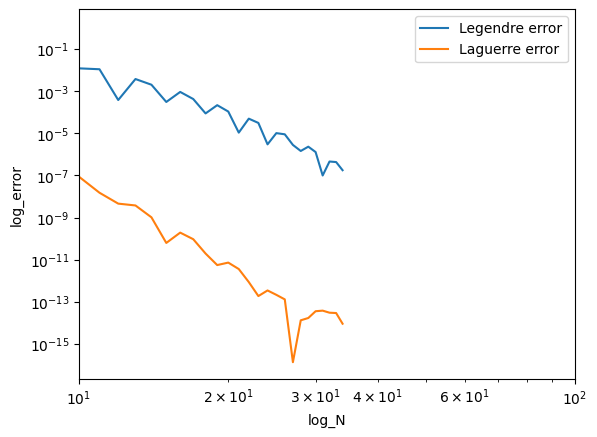

In [11]:
#Part Plotting Laguerre function and comparison
import math
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from numpy.polynomial import Legendre as P
from numpy.polynomial.laguerre import laggauss



    
    
# get N values
N_vals = df["N"].to_numpy(dtype = int)

# get error columns
eps_Gleg   = df["eps_Gleg"].to_numpy(dtype = float)
eps_Glag   = df["eps_Glag"].to_numpy(dtype = float)


#plotting parameters
plt.loglog(N_vals, eps_Gleg  , label="Legendre error")
plt.loglog(N_vals, eps_Glag, label="Laguerre error")

plt.legend(loc="best")
plt.xlim(10**1, 10**2)
plt.xlabel("log_N")
plt.ylabel("log_error")




"""

Laguere quadrature compared to Legedre has relative errors that converge faster and reach 
The machine precision limit is up to 10^-15 compared to 10^-7. This is one indicator that Laguerre quadrature converges faster. 

"""


